# Conditional Probabilities of AWGN Channel

COnditional probabilities and probability densities play a crucial role in communications and, even more generally, in statistical signal processing and machine learning. This Jupyter notebook shall explain some basic fundamentals.

## Continuous-Valued Information Signal

The transmission of data over an AWGN channel leads to an additive disturbance of the information signal $x$ by white Gaussian noise $n$. The received signal can be described by

\begin{equation}
  y = x + w \; .
\end{equation}

Usually, the information signal $x$ is statistically independent of the noise $n$ and the corresponding densities $p_{\cal X}(\xi)$ and $p_{\cal W}(\xi)$ are convolved in order to obtain the density $p_{\cal Y}(\xi)$ of the received signal $y$. 

\begin{equation}
  p_{\cal Y}(\xi) = p_{\cal X}(\xi) \ast p_{\cal W}(\xi) 
\end{equation}

The likelihood function is the conditional probability density of $y$ given $x$

\begin{equation}
  p_{{\cal Y} \mid {\cal X}=x}(y) = p_{\cal W}(y-x) 
  = \frac{p_{{\cal Y}, {\cal X}}(y,x)}{p_{\cal X}(x)}
\end{equation}

and denotes the noise probability density at the position $y-x$. It has to be emphasized that the likelihood function is only a regular probability density with respect to $y$ (integrating versus $y$ delivers the value 1). Regarding the signal $x$, $p_{{\cal Y} \mid {\cal X}=x}(y)$ is no density because the integral versus $x$ does not deliver the value 1. The likelihood function can be transformed into the a posteriori probability density by applyig Bayes rule

\begin{equation}
  p_{{\cal X} \mid {\cal Y}=y}(x)
  = \frac{p_{{\cal X}, {\cal Y}}(x,y)}{p_{\cal Y}(y)}
  = p_{{\cal Y} \mid {\cal X}=x}(y) \cdot \frac{p_{\cal X}(x)}{p_{\cal Y}(y)}   .
\end{equation}

For a zero-mean Gaussian distributed information signal $x(t)$, the a posteriori probability density is Gaussian as well with the parameters

\begin{align}
  \mu_{{\cal X} \mid y} &= \frac{\gamma}{\gamma+1} \cdot y \\
  \sigma_{{\cal X} \mid y}^2 &= \frac{\sigma_{\cal X}^2}{\gamma+1} \; .
\end{align}


<>:31: SyntaxWarning: invalid escape sequence '\c'
<>:31: SyntaxWarning: invalid escape sequence '\c'
/var/folders/jq/3mc3rmqn4zb76l6_gjt5w7xw0000gn/T/ipykernel_12973/3187655987.py:31: SyntaxWarning: invalid escape sequence '\c'
  plt.ylabel('$p_{{\cal X} \mid y}(x)$')


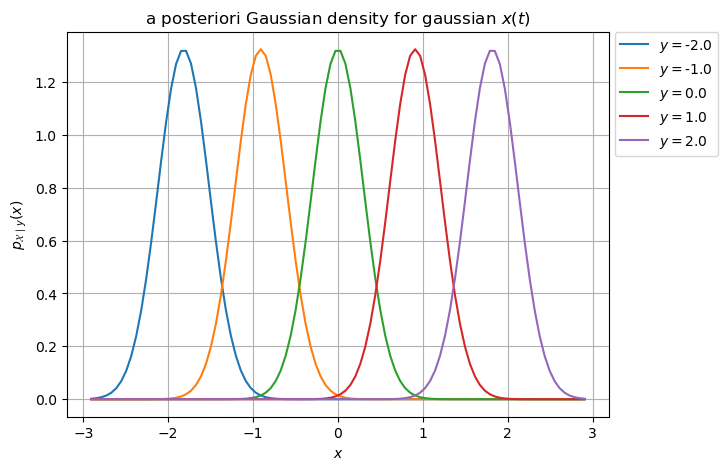

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# real gaussian distribution
# number of samples
N = 100
# variance
sigma2_W = 0.1

# variance of X
sigma2_X = 1.0
# received values
y = np.array((-2.0,-1.0,0.0,1.0,2.0))
# SNR
gamma = sigma2_X / sigma2_W
# conditional mean
mu_X_y = gamma / (gamma+1) * y
#conditional variance
sigma2_X_y = sigma2_X / (gamma+1)
# a posteriori densities
w_max = np.max(y) + 3.0*np.sqrt(sigma2_X_y)
w_real_app = np.linspace(-w_max,w_max,N)
X,Y = np.meshgrid(w_real_app,mu_X_y)
pdf_x_y = np.exp(-(X-Y)**2/2/sigma2_X_y) / np.sqrt(2. * np.pi * sigma2_X_y)

fig_app_gaussian = plt.figure(figsize=(7,5))
ax3 = fig_app_gaussian.add_subplot(111)
for run_y in np.arange(len(y)):
    ax3.plot(w_real_app, pdf_x_y[run_y,:],label='$y=$%.1f' %(y[run_y]))
plt.xlabel('$x$')
plt.ylabel('$p_{{\cal X} \mid y}(x)$')
plt.title('a posteriori Gaussian density for gaussian $x(t)$')
plt.grid(True)
plt.legend(bbox_to_anchor=(1.01, 1), loc='upper left', borderaxespad=0.)
plt.show()

We observe from the above figure that the conditional mean $\mu_{{\cal X} | y}$ depends on the received value $y$. Therefore, $y$ contains information about the information symbol $x$.

## Discrete Information Signal (BPSK)

For a BPSK signal containing the symbols $\mathbb{X}=\{-1,+1\}$ with probabilities $P_{-1}$ and $P_{+1}=1-P_{-1}$, the likelihood function becomes

\begin{align}
  p_{{\cal Y} \mid x = \pm 1}(y) 
  &= \frac{1}{\sqrt{2 \pi \sigma_{\cal N}^2}} 
      \cdot e^{- \frac{(y+\mp 1)^2}{2 \sigma_{\cal N}^2}} \; .
\end{align}

The probability density of the received signal now computes to

\begin{align}
  p_{\cal Y}(y) 
  &= P_{-1} \cdot p_{{\cal Y} \mid x=-1}(y) + P_{+1} \cdot p_{{\cal Y} \mid x=+1}(y) 
   = \frac{1-P_{+1}}{\sqrt{2 \pi \sigma_{\cal W}^2}} 
      \cdot e^{- \frac{(y+1)^2}{2 \sigma_{\cal W}^2}}
   + \frac{P_{+1}}{\sqrt{2 \pi \sigma_{\cal W}^2}} 
      \cdot e^{- \frac{(y-1)^2}{2 \sigma_{\cal W}^2}}  
\end{align}

For the considered binary alphabet $\mathbb{X}$, we obtain two a posteriori probabilities

\begin{align}
  \Pr\{ {\cal X} = +1 \mid y \} 
  &= \frac{p_{{\cal Y} \mid x=+1}(y) \cdot P_{+1}}{p_{\cal Y}(y)} 
   = \frac{p_{{\cal Y} \mid x=+1}(y) \cdot P_{+1}}
          {(1-P_{+1}) \cdot p_{{\cal Y} \mid x=-1}(y) 
            + P_{+1} \cdot p_{{\cal Y} \mid x=+1}(y) } \\
  &= \frac{ 1 }{ 1 + \frac{1-P_{+1}}{P_{+1}} \cdot 
                \frac{ p_{{\cal Y} \mid x=-1}(y)}{p_{{\cal Y} \mid x=+1}(y)} } 
   = \frac{1}{1 + \frac{1-P_{+1}}{P_{+1}} \cdot e^{- 2y / \sigma_{\cal W}^2} }
  \\
  \Pr\{ {\cal X} = -1 \mid y \} 
  &= \frac{p_{{\cal Y} \mid x=-1}(y) \cdot P_{-1}}{p_{\cal Y}(y)} 
   = \frac{p_{{\cal Y} \mid x=-1}(y) \cdot P_{-1}}
          {(1-P_{+1}) \cdot p_{{\cal Y} \mid x=-1}(y) 
            + P_{+1} \cdot p_{{\cal Y} \mid x=+1}(y) } \\
  &= \frac{1}{1 + \frac{P_{+1}}{1-P_{+1}} \cdot 
      \frac{p_{{\cal Y} \mid x=+1}(y)}{p_{{\cal Y} \mid x=-1}(y)} } 
   = \frac{1}{1 + \frac{P_{+1}}{1-P_{+1}} \cdot e^{2y / \sigma_{\cal W}^2} }
\end{align}

as functions of the received signal $y$. Combining the expressions for $x=+1$ and $x=-1$ we obtain

\begin{equation}
  \Pr\{ {\cal X} = x \mid y \} 
  = \frac{1}{1 + \left(\frac{1-P_{+1}}{P_{+1}}\right)^x \cdot e^{- 2xy / \sigma_{\cal W}^2} } \; .
\end{equation}

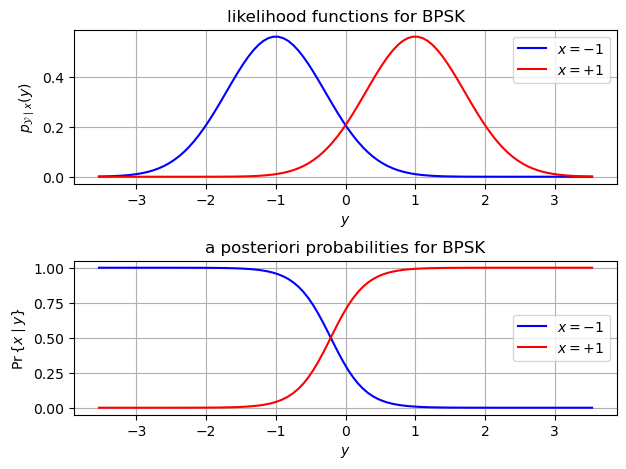

In [6]:
w_real = 5.0 * np.sqrt(sigma2_W) * np.linspace(-1,1,N)

# Likelihood functions for BPSK
pdf_y_x = np.zeros((len(w_real),2))
pdf_y_x[:,0] = np.exp(-(w_real+1)**2/2/sigma2_W) / np.sqrt(2*np.pi*sigma2_W)
pdf_y_x[:,1] = np.exp(-(w_real-1)**2/2/sigma2_W) / np.sqrt(2*np.pi*sigma2_W)

# a priori probability for +1
P_1 = 0.7
# a posteriori probabilities as functions of y
pdf_x_y = np.zeros((len(w_real),2))
# x = -1
pdf_x_y[:,0] = 1.0 / ( 1.0 + P_1/(1-P_1)*np.exp(2*w_real/sigma2_W) )
# x = -1
pdf_x_y[:,1] = 1.0 / ( 1.0 + (1-P_1)/P_1*np.exp(-2*w_real/sigma2_W) )


fig_app_BPSK = plt.figure(figsize=(7,5))
plt.subplots_adjust(hspace=0.5)

ax4 = fig_app_BPSK.add_subplot(211)
ax4.plot(w_real, pdf_y_x[:,0], 'b-', label='$x=-1$')
ax4.plot(w_real, pdf_y_x[:,1], 'r-', label='$x=+1$')
plt.xlabel('$y$')
plt.ylabel('$p_{{\\cal Y} \\mid x}(y)$')
plt.title('likelihood functions for BPSK')
plt.grid(True)
plt.legend()

ax4 = fig_app_BPSK.add_subplot(212)
ax4.plot(w_real, pdf_x_y[:,0], 'b-', label='$x=-1$')
ax4.plot(w_real, pdf_x_y[:,1], 'r-', label='$x=+1$')
plt.xlabel('$y$')
plt.ylabel('$\\Pr \\{ x \\mid y \\}$')
plt.title('a posteriori probabilities for BPSK')
plt.grid(True)
plt.legend()

plt.show()

From the first figure above we can conclude that the likelihood functions are equivalent to the Gaussian noise distribution but centered at the hypotheses $x = \pm 1$. 

Das lower figure illustrates the a posteriori probabilities. For $x=+1$, it tends to the value $1$ with growing $y \to \infty$. Contrarily, it approaches the value $-1$ for the opposite direction $y \to - \infty$ if $x=-1$ holds. The a posteriori probabilities represent the best measure for detecting the transmitted data symbol given the received symbol $y$.

\begin{equation}
    \hat{x} = \mathrm{argmax}_{\tilde{x}} \Pr \{ \tilde{x} \mid y \} \; .
\end{equation}

The intersection of the curves for $x=+1$ and $x=-1$ does not lie at $y=0$ if the symbols $x = \pm 1$ have different a priori probabilities. 

## Complex-Valued Discrete Information Signal (QPSK)

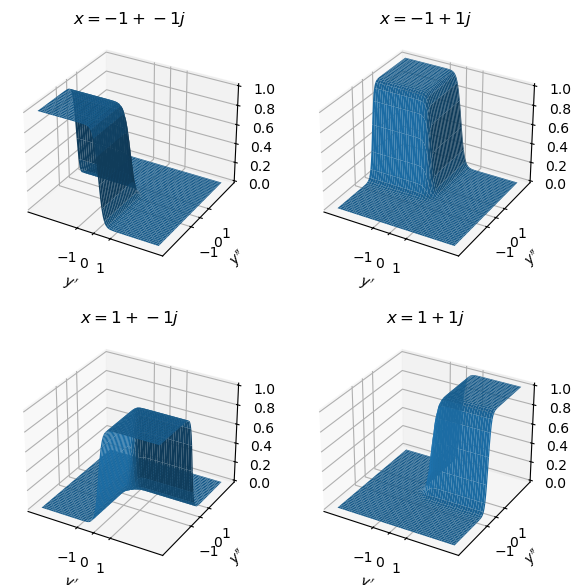

In [7]:
QPSK = ([-1-1j,-1+1j,1-1j,1+1j],[0.25,0.25,0.25,0.25])
sigma2_W = 0.5

wr,wi = np.meshgrid(w_real,w_real)
w_cmplx = (wr+1j*wi).flatten()
        
# determine p(y|x), p(y) and p(x|y)
pmf_y_x = np.zeros((len(w_cmplx),4))
pmf_x_y = np.zeros((len(w_cmplx),4))
pmf_y = np.zeros(len(w_cmplx))
cntrX = 0
for runx in QPSK[0]:
    tmp = np.exp(-np.abs(w_cmplx-runx)**2 / sigma2_W)
    pmf_y_x[:,cntrX] = tmp / np.sum(tmp)
    pmf_y += pmf_y_x[:,cntrX] * QPSK[1][cntrX]
    cntrX += 1

pmf_x_y = pmf_y_x * np.tile(QPSK[1],(len(w_cmplx),1)) / np.tile(pmf_y,(len(QPSK[0]),1)).transpose()

fig_app_QPSK = plt.figure(figsize=(7,7))
plt.subplots_adjust(hspace=0.25)

ax5 = fig_app_QPSK.add_subplot(221,projection='3d')
ax5.plot_surface(wr, wi, np.reshape(pmf_x_y[:,0],(len(w_real),len(w_real))))
plt.xlabel('$y^\\prime$')
plt.ylabel('$y^{\\prime \\prime}$')
plt.title('$x=%g+%gj$' %(np.real(QPSK[0][0]),np.imag(QPSK[0][0])))
plt.xticks([-1,0,1])
plt.yticks([-1,0,1])
plt.grid(True)

ax5 = fig_app_QPSK.add_subplot(222,projection='3d')
ax5.plot_surface(wr, wi, np.reshape(pmf_x_y[:,1],(len(w_real),len(w_real))))
plt.xlabel('$y^\\prime$')
plt.ylabel('$y^{\\prime \\prime}$')
plt.title('$x=%g+%gj$' %(np.real(QPSK[0][1]),np.imag(QPSK[0][1])))
plt.xticks([-1,0,1])
plt.yticks([-1,0,1])
plt.grid(True)

ax5 = fig_app_QPSK.add_subplot(223,projection='3d')
ax5.plot_surface(wr, wi, np.reshape(pmf_x_y[:,2],(len(w_real),len(w_real))))
plt.xlabel('$y^\\prime$')
plt.ylabel('$y^{\\prime \\prime}$')
plt.title('$x=%g+%gj$' %(np.real(QPSK[0][2]),np.imag(QPSK[0][2])))
plt.xticks([-1,0,1])
plt.yticks([-1,0,1])
plt.grid(True)

ax5 = fig_app_QPSK.add_subplot(224,projection='3d')
ax5.plot_surface(wr, wi, np.reshape(pmf_x_y[:,3],(len(w_real),len(w_real))))
plt.xlabel('$y^\\prime$')
plt.ylabel('$y^{\\prime \\prime}$')
plt.title('$x=%g+%gj$' %(np.real(QPSK[0][3]),np.imag(QPSK[0][3])))
plt.xticks([-1,0,1])
plt.yticks([-1,0,1])
plt.grid(True)

plt.show()

From the figures above, we see that the a posteriori probabilities have the same interpretation in the complex case as for the real case. The complex received signal $y=y^\prime + j y^{\prime \prime}$ allows a reliable detection of the QPSK symbol $x$, if its magnitude is large. In this case, the received symbol is far away from the origine and lies with high probability in the same quadrant as the transmitted symbol. In the vicinity of the origine, however, all four a posteriori probabilities are more or less equal and a decision is rather unreliable.